# Multi-session spectra: does Figure 2 replicate across 48 rat sessions?

Section 2 established two differences between waking and sleep in one session
(Achilles, 122 neurons): waking's variance spectrum decays faster, and only in
waking is a pure power law improved on by one with an exponential cutoff.

This notebook asks whether either finding holds across the 48 rat sessions of
the public databank pack, using the same procedure throughout: ordinary least
squares for the exponent, and the `powerlaw` package (Alstott et al., 2014) for
the distributional fit and the model comparisons.

Two conventions carried over from `../scripts/analysis_config.py`:

* the **exponent** is compared at a matched population of 25 units over
  components 3-20, because sessions differ in how many units they record;
* the **goodness of fit** is computed on each session's full retained
  population over its own data-selected cutoff, because a 25-eigenvalue
  spectrum is too short for a likelihood fit.


## Setup and conventions

In [1]:
import os, sys, warnings
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

sys.path.insert(0, os.path.abspath("../scripts"))
from analysis_config import BIN, THRESH, N_SUB, N_DRAWS, SEED, FIT_RANGE_MATCHED, FIT_RANGE_FULL
import dandi_data
import powerlaw

STATES = ["Wake", "NREM", "REM"]
COLORS = {"Wake": "#D55E00", "NREM": "#0072B2", "REM": "#009E73"}
REGCOL = {"rat CA1": "#7B3294", "rat hippocampus": "#008837",
          "rat amygdala": "#E66101", "rat frontal cortex": "#0571B0"}
GOF_REPS = 200          # bootstrap replicates for the goodness-of-fit p
RECOMPUTE_GOF = False   # True re-runs the fits (~45 min); False loads multisession_gof.csv
MIN_UNITS_GOF = 40      # a likelihood fit below this is not reported
MIN_BINS = 300          # a state with fewer bins than this is not fitted

mpl.rcParams.update({"font.size": 9, "axes.titlesize": 9, "axes.labelsize": 9,
                     "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 7.5,
                     "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight"})

print("powerlaw", powerlaw.__version__, "| bin", BIN, "s | tonic threshold", THRESH, "Hz")
print("matched population", N_SUB, "units over PCs", FIT_RANGE_MATCHED,
      "| full population over PCs", FIT_RANGE_FULL)

powerlaw 1.4.4 | bin 1.0 s | tonic threshold 4.71 Hz
matched population 25 units over PCs (3, 20) | full population over PCs (3, 50)


## 1. What is in the pack

Every session that survives the 25-unit floor, split by region.

In [2]:
# Sessions come from dandi_data.load_pack, the same loader the rest of the rat
# analysis uses: it applies the tonic-rate exclusion, maps Quiet to Wake, and
# splits dandiset 000061 into its hippocampal and amygdalar populations.
rows, DATA = [], {}
for s in dandi_data.load_pack(min_units=N_SUB):
    key = (s["tag"], s["group"])
    DATA[key] = s
    counts = {st: int((s["state"] == st).sum()) for st in STATES}
    rows.append(dict(tag=s["tag"], group=s["group"], dandiset=s["tag"].split("_")[0],
                     n_units=s["n_units"], n_bins=int(len(s["state"])), **{f"bins_{k}": v for k, v in counts.items()}))

inv = pd.DataFrame(rows).sort_values(["group", "tag"]).reset_index(drop=True)
inv["gof_eligible"] = inv.n_units >= MIN_UNITS_GOF
inv.to_csv("multisession_inventory.csv", index=False)

print("populations:", len(inv), "from", inv.tag.nunique(), "sessions")
print(inv.groupby("group").agg(n=("tag", "size"), units_median=("n_units", "median"),
                               gof_eligible=("gof_eligible", "sum")).to_string())
short = inv[(inv[[f"bins_{s}" for s in STATES]] < MIN_BINS).any(axis=1)]
print("\npopulations with a state under", MIN_BINS, "bins:", len(short))
print(inv[[f"bins_{s}" for s in STATES]].describe().loc[["min", "50%", "max"]].round(0).to_string())

populations: 55 from 44 sessions
                     n  units_median  gof_eligible
group                                             
rat CA1              8          64.5             8
rat amygdala        20         102.0            19
rat frontal cortex  16          45.5             9
rat hippocampus     11          38.0             5

populations with a state under 300 bins: 3
     bins_Wake  bins_NREM  bins_REM
min     1365.0     1453.0     108.0
50%    13502.0     8360.0    1339.0
max    20688.0    21573.0    3845.0


## 2. Spectra

Two spectra per session and state: the full retained population, and the
mean over 20 random subsamples of 25 units.

In [3]:
import zlib
from analysis_config import MIN_SPIKES_STATE, effective_range

def spectrum(M):
    """Eigenvalue spectrum as a fraction of total variance (columns centred)."""
    M = M - M.mean(0)
    ev = np.linalg.svd(M, compute_uv=False) ** 2
    return ev / ev.sum()

def ols_exponent(ev, fit_range):
    """OLS of log(lambda_k) on log(k). Returns (alpha, R2, range actually used)."""
    lo, hi = effective_range(fit_range, len(ev))
    k = np.arange(lo, hi + 1)
    y = np.log(np.sort(ev)[::-1][lo - 1:hi])
    a, b = np.polyfit(np.log(k), y, 1)
    resid = y - (a * np.log(k) + b)
    return -a, float(1 - resid.var() / y.var()), (lo, hi)

def session_rng(tag, group):
    """Deterministic per-population stream.

    zlib.crc32 rather than hash(): Python salts string hashing per process, so
    hash() would give a different subsample on every run and the matched
    exponents would not reproduce.
    """
    return np.random.default_rng(zlib.crc32(f"{tag}|{group}|{SEED}".encode()))

In [4]:
rows, SPEC = [], {}
for (tag, group), s in DATA.items():
    rng = session_rng(tag, group)
    for st in STATES:
        m = s["state"] == st
        if m.sum() < MIN_BINS:
            continue
        Xs = s["X"][m]
        active = Xs.sum(0) >= MIN_SPIKES_STATE          # a unit must fire in the state fitted
        Xs = Xs[:, active]
        if Xs.shape[1] < N_SUB:
            continue
        ev_full = spectrum(Xs)
        a_full, r2_full, rng_full = ols_exponent(ev_full, FIT_RANGE_FULL)

        draws = [spectrum(Xs[:, np.sort(rng.choice(Xs.shape[1], N_SUB, replace=False))])
                 for _ in range(N_DRAWS)]
        ev_match = np.mean(draws, axis=0)
        a_match, r2_match, rng_match = ols_exponent(ev_match, FIT_RANGE_MATCHED)

        SPEC[(tag, group, st)] = dict(full=ev_full, matched=ev_match)
        rows.append(dict(tag=tag, group=group, state=st, n_bins=int(m.sum()),
                         n_units_state=int(active.sum()),
                         a_full=a_full, r2_full=r2_full,
                         fit_lo_full=rng_full[0], fit_hi_full=rng_full[1],
                         a_matched=a_match, r2_matched=r2_match,
                         active_frac=float((Xs > 0).mean())))

EXP = pd.DataFrame(rows)
EXP.to_csv("multisession_exponents.csv", index=False)
np.savez_compressed("multisession_spectra.npz",
                    **{f"{k[2]}__{k[1].replace(' ', '-')}__{k[0]}__{w}": v[w]
                       for k, v in SPEC.items() for w in ("full", "matched")})

print("spectra:", len(EXP), "session-state fits |", EXP.tag.nunique(), "sessions")
print(EXP.groupby("state")[["a_matched", "a_full", "r2_matched", "n_units_state"]].median().round(3).to_string())
print("\nfull-population fit range truncated below 3-50 in",
      int((EXP.fit_hi_full < FIT_RANGE_FULL[1]).sum()), "of", len(EXP), "fits",
      "| median effective hi:", int(EXP.fit_hi_full.median()))

spectra: 159 session-state fits | 43 sessions
       a_matched  a_full  r2_matched  n_units_state
state                                              
NREM       1.152   1.073       0.968           58.5
REM        1.225   1.155       0.954           59.0
Wake       1.519   1.425       0.956           58.5

full-population fit range truncated below 3-50 in 55 of 159 fits | median effective hi: 50


## 3. Distributional fit and model comparison

Runs on the full-population spectra, with the `powerlaw` package doing the
fitting. The bootstrap is the expensive part; the cache switch in the setup
cell avoids refitting on every run.

In [5]:
# Distributional fit and model comparison, full-population spectra only.
# Everything here comes from the `powerlaw` package: Fit() scans candidate
# cutoffs, fits the tail index by maximum likelihood above each and keeps the
# one minimising the Kolmogorov-Smirnov distance; distribution_compare()
# returns Vuong's normalised likelihood ratio for the non-nested alternatives
# and the classical nested test for the truncated power law.
#
# The bootstrap p is the Clauset semi-parametric test: synthetic datasets are
# drawn from the fitted law, the body resampled from the observed sub-cutoff
# values, and the whole cutoff scan re-run on each. It is reported for
# completeness; on data of this kind it is conservative, because its replicates
# are independent draws and vary more than eigenvalues of one covariance
# matrix do.

ALTS = ["lognormal", "exponential", "truncated_power_law"]

def bootstrap_p(ev, fit, reps, rng):
    xmin, alpha, D = fit.power_law.xmin, fit.power_law.alpha, fit.power_law.D
    n, body = len(ev), ev[ev < xmin]
    frac = float((ev >= xmin).mean())
    worse = 0
    for _ in range(reps):
        k = int((rng.random(n) < frac).sum())
        tail = xmin * (1 - rng.random(k)) ** (-1 / (alpha - 1))
        rest = rng.choice(body, n - k, replace=True) if len(body) and n - k else np.empty(0)
        synth = np.concatenate([tail, rest])
        worse += powerlaw.Fit(synth, discrete=False, verbose=False).power_law.D >= D
    return worse / reps

def fit_one(ev, reps, rng):
    f = powerlaw.Fit(ev, discrete=False, verbose=False)
    pl = f.power_law
    out = dict(xmin=pl.xmin, alpha_mle=pl.alpha, alpha_se=pl.sigma, ks_D=pl.D,
               n_tail=int(pl.n), n_eig=len(ev))
    for alt in ALTS:
        R, p = f.distribution_compare("power_law", alt, normalized_ratio=True)
        out[f"R_{alt}"], out[f"p_{alt}"] = R, p
    out["p_boot"] = bootstrap_p(ev, f, reps, rng)
    return out

if not RECOMPUTE_GOF and os.path.exists("multisession_gof.csv"):
    GOF = pd.read_csv("multisession_gof.csv")
    print("loaded cached fits; set RECOMPUTE_GOF = True to refit")
else:
    gof_rows = []
    for i, ((tag, group, st), sp) in enumerate(SPEC.items(), 1):
        if i % 25 == 0:
            print(f"  {i}/{len(SPEC)}", flush=True)
        e = EXP[(EXP.tag == tag) & (EXP.group == group) & (EXP.state == st)].iloc[0]
        if e.n_units_state < MIN_UNITS_GOF:
            continue
        rec = dict(tag=tag, group=group, state=st, n_bins=int(e.n_bins),
                   n_units=int(e.n_units_state), a_ols_full=e.a_full, a_ols_matched=e.a_matched)
        rec.update(fit_one(sp["full"], GOF_REPS, session_rng(tag, group)))
        rec["a_converted"] = 1.0 / (rec["alpha_mle"] - 1.0)
        gof_rows.append(rec)

    GOF = pd.DataFrame(gof_rows)
    GOF.to_csv("multisession_gof.tmp.csv", index=False)
    os.replace("multisession_gof.tmp.csv", "multisession_gof.csv")

print(len(GOF), "fits |", GOF.tag.nunique(), "sessions")
print(GOF.groupby("state")[["alpha_mle", "ks_D", "p_boot", "n_tail"]].median().round(3).to_string())

loaded cached fits; set RECOMPUTE_GOF = True to refit
118 fits | 35 sessions
       alpha_mle   ks_D  p_boot  n_tail
state                                  
NREM       2.341  0.071   0.725    30.0
REM        2.284  0.089   0.585    25.5
Wake       2.116  0.079   0.540    29.0


## 4. Does the state ordering replicate?

In [6]:
from scipy.stats import wilcoxon

piv = EXP.pivot_table(index=["tag", "group"], columns="state", values="a_matched").dropna()
piv["region"] = [g for _, g in piv.index]

rows = []
for region, d in list(piv.groupby("region")) + [("ALL", piv)]:
    for s1, s2 in (("Wake", "NREM"), ("Wake", "REM"), ("NREM", "REM")):
        diff = d[s1] - d[s2]
        stat = wilcoxon(diff) if len(diff) >= 6 else None
        rows.append(dict(region=region, pair=f"{s1}-{s2}", n=len(diff),
                         frac_positive=float((diff > 0).mean()),
                         median_diff=float(diff.median()),
                         p_wilcoxon=float(stat.pvalue) if stat else np.nan))
ORD = pd.DataFrame(rows)
ORD.to_csv("multisession_ordering.csv", index=False)
print(ORD.round(4).to_string(index=False))
print("\nmedian matched exponent by state and region:")
print(piv.groupby("region")[STATES].median().round(3).to_string())

            region      pair  n  frac_positive  median_diff  p_wilcoxon
           rat CA1 Wake-NREM  8         1.0000       0.3662      0.0078
           rat CA1  Wake-REM  8         1.0000       0.3053      0.0078
           rat CA1  NREM-REM  8         0.3750      -0.0555      0.4609
      rat amygdala Wake-NREM 20         1.0000       0.3986      0.0000
      rat amygdala  Wake-REM 20         0.9500       0.3846      0.0000
      rat amygdala  NREM-REM 20         0.2000      -0.0534      0.0153
rat frontal cortex Wake-NREM 12         0.9167       0.3208      0.0010
rat frontal cortex  Wake-REM 12         0.5833       0.0488      0.7910
rat frontal cortex  NREM-REM 12         0.0833      -0.2067      0.0010
   rat hippocampus Wake-NREM 11         1.0000       0.6224      0.0010
   rat hippocampus  Wake-REM 11         1.0000       0.4197      0.0010
   rat hippocampus  NREM-REM 11         0.0909      -0.2028      0.0137
               ALL Wake-NREM 51         0.9804       0.3991     

## 5. Does the shape difference replicate?

The single session found an upper cutoff in waking and in neither sleep
state. Across sessions the pattern is different, and the comparison is read
against the 5 % false-alarm rate measured by simulation in Section 2.

In [7]:
# Calibration from simulation (Section 2): on data that genuinely are power
# laws of this size, the truncated comparison raises a false alarm in 5 % of
# cases and the exponential comparison identifies the power law in 56 %, while
# the log-normal comparison discriminates nothing in either direction.
FALSE_ALARM = 0.05

def preference(G, alt, thresh):
    """Fraction of fits in which the alternative is preferred (R < 0) at p < thresh."""
    sub = G.dropna(subset=[f"p_{alt}"])
    return float(((sub[f"R_{alt}"] < 0) & (sub[f"p_{alt}"] < thresh)).mean())

def supports_pl(G, alt, thresh):
    """Fraction in which the power law is preferred (R > 0) at p < thresh."""
    sub = G.dropna(subset=[f"p_{alt}"])
    return float(((sub[f"R_{alt}"] > 0) & (sub[f"p_{alt}"] < thresh)).mean())

rows = []
for region, dr in list(GOF.groupby("group")) + [("ALL", GOF)]:
    for st, d in dr.groupby("state"):
        rows.append(dict(region=region, state=st, n=len(d),
                         truncated_preferred_p05=preference(d, "truncated_power_law", .05),
                         truncated_preferred_p10=preference(d, "truncated_power_law", .10),
                         powerlaw_over_exponential_p05=supports_pl(d, "exponential", .05),
                         lognormal_preferred_p05=preference(d, "lognormal", .05),
                         powerlaw_over_lognormal_p05=supports_pl(d, "lognormal", .05),
                         median_ks_D=float(d.ks_D.median()), median_p_boot=float(d.p_boot.median())))
CMP = pd.DataFrame(rows).sort_values(["region", "state"])
CMP.to_csv("multisession_model_comparison.csv", index=False)
print("fraction of populations preferring the truncated form (p < 0.05);",
      f"false-alarm rate on true power laws is {FALSE_ALARM:.0%}")
print(CMP[CMP.region == "ALL"].round(3).to_string(index=False))
print()
print(CMP[CMP.region != "ALL"][["region", "state", "n", "truncated_preferred_p05",
                                "powerlaw_over_exponential_p05"]].round(3).to_string(index=False))

fraction of populations preferring the truncated form (p < 0.05); false-alarm rate on true power laws is 5%
region state  n  truncated_preferred_p05  truncated_preferred_p10  powerlaw_over_exponential_p05  lognormal_preferred_p05  powerlaw_over_lognormal_p05  median_ks_D  median_p_boot
   ALL  NREM 40                    0.050                    0.125                          0.200                    0.050                          0.0        0.071          0.725
   ALL   REM 38                    0.316                    0.421                          0.079                    0.026                          0.0        0.089          0.585
   ALL  Wake 40                    0.300                    0.350                          0.125                    0.000                          0.0        0.079          0.540

            region state  n  truncated_preferred_p05  powerlaw_over_exponential_p05
           rat CA1  NREM  8                    0.000                          0.750
       

## 5b. Is the exponent shared across populations?

Before any exponent is quoted for a whole dataset, the standard check is
whether the individual fits are compatible with a single common exponent.


In [8]:
# ---- Do populations share a common exponent? (Navas-Portella et al. 2019)
# Likelihood-ratio test of one exponent for all populations in a group against
# one exponent per population, computed on each population's own fitted tail:
#     ll_k(a) = n_k [log(a - 1) - log xmin_k] - a * S_k,   S_k = sum log(x / xmin_k)
# Common MLE a_c = 1 + N / sum(S_k); statistic 2[sum ll_k(a_k) - sum ll_k(a_c)]
# is chi-squared with K - 1 degrees of freedom. Rejection means a merged fit is
# not licensed and the per-population distribution must be reported instead.
from scipy.stats import chi2

def common_exponent_test(rows):
    S, n, a_ind = [], [], []
    for _, r in rows.iterrows():
        ev = SPEC[(r.tag, r.group, r.state)]["full"]
        t = ev[ev >= r.xmin]
        s = float(np.sum(np.log(t / r.xmin)))
        S.append(s); n.append(len(t)); a_ind.append(1 + len(t) / s)
    S, n, a_ind = np.array(S), np.array(n), np.array(a_ind)
    a_c = 1 + n.sum() / S.sum()
    stat = 2 * (np.sum(n * np.log(a_ind - 1) - a_ind * S)
                - np.sum(n * np.log(a_c - 1) - a_c * S))
    return dict(K=len(n), a_common=a_c, stat=stat, df=len(n) - 1,
                p=float(chi2.sf(stat, len(n) - 1)), a_min=a_ind.min(), a_max=a_ind.max())

res = []
for st in STATES:
    d = GOF[GOF.state == st]
    res.append(dict(group="all populations", state=st, **common_exponent_test(d)))
    for g, dg in d.groupby("group"):
        if len(dg) >= 4:
            res.append(dict(group=g, state=st, **common_exponent_test(dg)))
CE = pd.DataFrame(res)
CE.to_csv("multisession_common_exponent.csv", index=False)
print(CE.round(3).to_string(index=False))
print("\nNote: failing to reject is not evidence of equality -- groups with few")
print("populations have little power, so only the rejections are informative.")

             group state  K  a_common    stat  df     p  a_min  a_max
   all populations  Wake 40     1.910 111.625  39 0.000  1.599  2.989
           rat CA1  Wake  8     2.176   3.367   7 0.849  2.065  2.835
      rat amygdala  Wake 19     1.847  61.403  18 0.000  1.645  2.989
rat frontal cortex  Wake  8     2.131   3.260   7 0.860  2.018  2.848
   rat hippocampus  Wake  5     1.802  13.965   4 0.007  1.599  2.504
   all populations  NREM 40     2.255  66.580  39 0.004  1.768  2.980
           rat CA1  NREM  8     2.177  18.102   7 0.012  1.768  2.763
      rat amygdala  NREM 19     2.258  34.077  18 0.012  1.851  2.805
rat frontal cortex  NREM  8     2.329   6.693   7 0.461  1.969  2.661
   rat hippocampus  NREM  5     2.285   5.800   4 0.215  1.983  2.980
   all populations   REM 38     2.168  70.083  37 0.001  1.805  2.986
           rat CA1   REM  8     2.390  14.788   7 0.039  1.831  2.985
      rat amygdala   REM 19     2.098  33.620  18 0.014  1.805  2.933
rat frontal cortex  

## 5c. Robustness to the neuron floor

Populations range from 25 to 160 neurons. Raising the floor to 60 keeps
25 populations and costs most of the non-amygdalar ones, so it is a check
rather than the main analysis.


In [9]:
# ---- Robustness: does a stricter neuron floor change anything?
# The exponent comparison is unaffected by construction (every population is cut
# to 25 units), so this tests the distributional side, where a larger population
# means a longer eigenvalue tail and more power to detect a cutoff.
from scipy.stats import wilcoxon, binomtest

def summarise(min_units):
    g = GOF[GOF.n_units >= min_units]
    keys = set(zip(g.tag, g.group))
    p = piv[[k in keys for k in piv.index]]
    out = dict(floor=min_units, populations=len(p), recordings=g.tag.nunique(),
               wake_gt_nrem=f"{int((p.Wake > p.NREM).sum())}/{len(p)}",
               med_Wake=float(p.Wake.median()), med_NREM=float(p.NREM.median()),
               med_REM=float(p.REM.median()),
               p_wilcoxon=float(wilcoxon(p.Wake - p.NREM).pvalue))
    for st in STATES:
        d = g[g.state == st]
        k = int(((d.R_truncated_power_law < 0) & (d.p_truncated_power_law < .05)).sum())
        out[f"trunc_{st}"] = f"{k}/{len(d)}"
        out[f"p_{st}"] = float(binomtest(k, len(d), FALSE_ALARM, alternative="greater").pvalue)
    return out

ROB = pd.DataFrame([summarise(u) for u in (MIN_UNITS_GOF, 60)])
ROB.to_csv("multisession_robustness.csv", index=False)
print(ROB.round(4).to_string(index=False))
print("\nregion mix at the stricter floor:",
      dict(GOF[GOF.n_units >= 60].drop_duplicates(["tag", "group"]).group.value_counts()))

 floor  populations  recordings wake_gt_nrem  med_Wake  med_NREM  med_REM  p_wilcoxon trunc_Wake  p_Wake trunc_NREM  p_NREM trunc_REM  p_REM
    40           38          35        38/38    1.5624    1.1532   1.2068         0.0      12/40     0.0       2/40  0.6009     12/38    0.0
    60           25          24        25/25    1.5547    1.1566   1.1799         0.0      10/25     0.0       2/25  0.3576      9/24    0.0

region mix at the stricter floor: {'rat amygdala': 17, 'rat CA1': 5, 'rat frontal cortex': 2, 'rat hippocampus': 1}


## 6. Figures

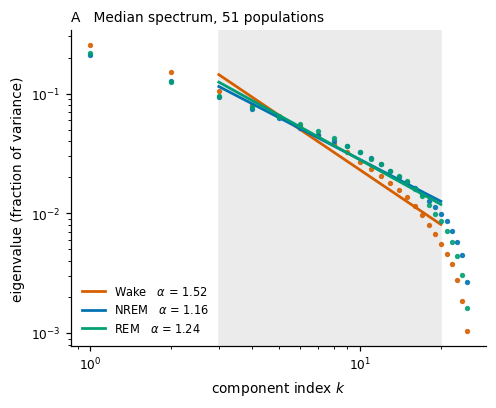

In [10]:
# ---- Figure 4A: median spectrum per state, in the format of Fig. 2A
# One curve per state: the median over populations of the matched-N spectrum,
# with the power-law fit drawn over the shaded range it was fitted on.
LO, HI = FIT_RANGE_MATCHED
med_spec = {s: np.median([SPEC[k]["matched"] for k in SPEC if k[2] == s], axis=0) for s in STATES}

fig, ax = plt.subplots(figsize=(4.4, 3.6), constrained_layout=True)
kk = np.arange(1, N_SUB + 1)
for s in STATES:
    ev = med_spec[s]
    ax.loglog(kk, ev, ".", ms=5, color=COLORS[s], alpha=.85)
    a, b = np.polyfit(np.log(kk[LO-1:HI]), np.log(ev[LO-1:HI]), 1)
    ax.loglog(kk[LO-1:HI], np.exp(b) * kk[LO-1:HI] ** a, "-", lw=1.8, color=COLORS[s],
              label=f"{s}   $\\alpha$ = {-a:.2f}")
ax.axvspan(LO, HI, color="0.92", zorder=0)
ax.set_xlabel("component index $k$")
ax.set_ylabel("eigenvalue (fraction of variance)")
ax.set_title(f"A   Median spectrum, {len(piv)} populations", loc="left")
ax.legend(frameon=False, loc="lower left")
ax.spines[["top", "right"]].set_visible(False)
fig.savefig("figures/fig4a_spectra_by_state.png")

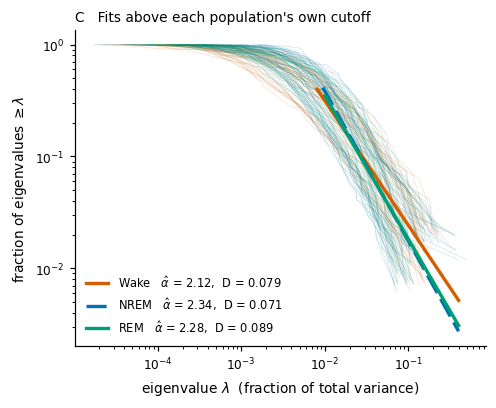

In [12]:
# ---- Figure 4C: goodness of fit, in the format of Fig. 2C
# Thin lines: every population's empirical CCDF. Thick lines: a power law with
# the median fitted exponent and median cutoff of that state. Non-REM is dashed
# because its fit nearly coincides with REM's.
DASH = {"Wake": (0, ()), "NREM": (0, (6, 2)), "REM": (0, ())}
fig, ax = plt.subplots(figsize=(4.4, 3.6), constrained_layout=True)
for s in STATES:
    sub = GOF[GOF.state == s]
    for _, r in sub.iterrows():
        ev = np.sort(SPEC[(r.tag, r.group, s)]["full"])[::-1]
        n = len(ev)
        ax.loglog(ev, np.arange(1, n + 1) / n, "-", lw=.5, color=COLORS[s], alpha=.18, zorder=2)
    xm, al = sub.xmin.median(), sub.alpha_mle.median()
    fx = np.geomspace(xm, 0.4, 100)
    ax.loglog(fx, (sub.n_tail.median() / sub.n_eig.median()) * (fx / xm) ** (1 - al), "-",
              lw=2.2, color=COLORS[s], dashes=DASH[s][1] or (None, None), zorder=3,
              label=f"{s}   $\\hat{{\\alpha}}$ = {al:.2f},  D = {sub.ks_D.median():.3f}")
ax.set_xlabel("eigenvalue $\\lambda$  (fraction of total variance)")
ax.set_ylabel("fraction of eigenvalues $\\geq \\lambda$")
ax.set_title("C   Fits above each population's own cutoff", loc="left")
ax.legend(frameon=False, loc="lower left")
ax.spines[["top", "right"]].set_visible(False)
fig.savefig("figures/fig4c_goodness_of_fit.png")

n = 54 populations | non-REM > waking in 40, Wilcoxon p = 6.0e-07
         Wake   NREM    REM
Q1      0.235  0.299  0.276
median  0.274  0.325  0.307
Q3      0.315  0.372  0.343


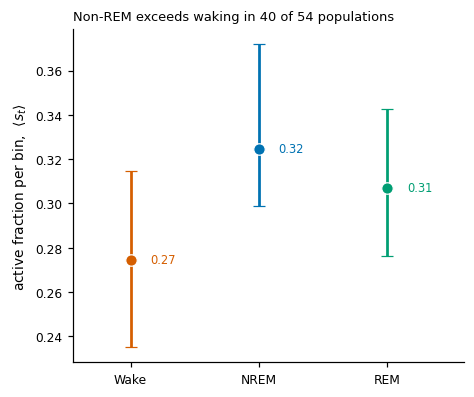

In [14]:
# Recruitment by state across populations (Fig. 4, sparseness panel).
# One value per population per state: the mean fraction of the retained
# population firing in a 1 s bin, averaged over all bins of that state.
# Marker = median over populations, bar = interquartile range (the middle
# half of the populations). The bars describe spread BETWEEN recordings,
# not uncertainty in the median; the claim in the title is a paired
# comparison within each population.
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon

STATES = ("Wake", "NREM", "REM")
COL = {"Wake": "#D55E00", "NREM": "#0072B2", "REM": "#009E73"}
PAIRED_LINES = False          # True draws one grey line per population

M = pd.read_csv("rat_session_metrics.csv")
M = M[M[[f"active_{s}" for s in STATES]].notna().all(1)]
V = M[[f"active_{s}" for s in STATES]].values
n_nw = int((M.active_NREM > M.active_Wake).sum())
p_nw = wilcoxon(M.active_NREM - M.active_Wake).pvalue

fig, ax = plt.subplots(figsize=(4.2, 3.5), constrained_layout=True)
x = np.arange(3)
if PAIRED_LINES:
    for row in V:
        ax.plot(x, row, "-", color="0.75", lw=.5, alpha=.55, zorder=1)
for i, st in enumerate(STATES):
    q1, med, q3 = np.percentile(V[:, i], [25, 50, 75])
    ax.errorbar(i, med, yerr=[[med - q1], [q3 - med]], fmt="o", ms=7.5,
                color=COL[st], capsize=4, lw=1.8, zorder=3, mec="white", mew=.8)
    ax.annotate(f"{med:.2f}", (i, med), textcoords="offset points",
                xytext=(13, -2), fontsize=7.5, color=COL[st])
ax.set_xticks(x); ax.set_xticklabels(STATES); ax.set_xlim(-.45, 2.6)
ax.set_ylabel(r"active fraction per bin,  $\langle s_t \rangle$")
ax.set_title(f"Non-REM exceeds waking in {n_nw} of {len(M)} populations",
             loc="left", fontsize=8.5)
ax.spines[["top", "right"]].set_visible(False)
fig.savefig("figures/fig4_sparseness_by_state.png", dpi=300, bbox_inches="tight")

print(f"n = {len(M)} populations | non-REM > waking in {n_nw}, Wilcoxon p = {p_nw:.1e}")
print(pd.DataFrame({s: np.percentile(M[f"active_{s}"], [25, 50, 75]).round(3)
                    for s in STATES}, index=["Q1", "median", "Q3"]).to_string())